# SHIELD vs STRIKE: evaluation against blind baselines (Colab)
*New file, not from the starter code (byzantine_skew / STRIKE).*

Compares **SHIELD** with the defenses that can report selection metrics (**Multi-Krum, Bulyan, Aksel, DnC**) under **STRIKE**, using
**accuracy, precision, recall and benign false-positive rate**. Precision/recall/FPR are computed on the *rejected* updates against simulator ground truth.

**Fairness setup:** every baseline runs *blind* (`--blind_defenses`): it receives an assumed Byzantine count `floor(ratio x n_sampled)` instead of the true count.
Main ratio = SHIELD's rejection cap (0.5); a second ratio (0.2) is a sensitivity check. Note that SHIELD's cap is only a *ceiling* (it rejects what its threshold flags),
while Krum/DnC/Bulyan treat the assumed count as the number to remove every round, so baselines at 0.5 are expected to over-reject benign clients.

Not included: Median, RFA, CClip, trimmed mean and mean (no per-update decision, so no precision/recall), and MDA (enumerates ~C(50,25) subsets, infeasible).

**Before running:** Runtime > Change runtime type > **T4 GPU**, and the repo you clone must contain the SHIELD code (commit and push first).

## 1. GPU check

In [1]:
# * confirm a GPU is attached (the starter code calls .cuda() directly)
!nvidia-smi
import torch
assert torch.cuda.is_available(), 'No GPU: Runtime > Change runtime type > T4 GPU'

Sun Nov 22 23:21:24 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   35C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Get the code

In [2]:
# * option A: clone from GitHub (must contain the SHIELD code). option B: leave REPO_URL empty and upload a zip
REPO_URL = 'https://github.com/edominicduke/SHIELD.git'
import os, shutil, zipfile
%cd /content
shutil.rmtree('/content/SHIELD', ignore_errors=True)
if REPO_URL:
    !git clone {REPO_URL} SHIELD
else:
    from google.colab import files
    up = files.upload()                     # * pick the zip of the SHIELD folder
    name = next(iter(up))
    os.makedirs('/content/SHIELD', exist_ok=True)
    with zipfile.ZipFile(name) as z:
        z.extractall('/content/SHIELD')
    entries = os.listdir('/content/SHIELD')
    if 'main.py' not in entries and len(entries) == 1:
        inner = os.path.join('/content/SHIELD', entries[0])
        for e in os.listdir(inner):
            shutil.move(os.path.join(inner, e), '/content/SHIELD')
%cd /content/SHIELD
assert os.path.exists('main.py'), 'main.py not found; check the upload'
# * sanity check that this checkout has the SHIELD code
assert os.path.exists('fl/defender/shield.py'), 'fl/defender/shield.py missing: commit and push the SHIELD code first'
!ls

/content
Cloning into 'SHIELD'...
remote: Enumerating objects: 139, done.
remote: Counting objects: 100% (139/139), done.
remote: Compressing objects: 100% (70/70), done.
remote: Total 139 (delta 74), reused 130 (delta 67), pack-reused 0 (from 0)
Receiving objects: 100% (139/139), 245.97 KiB | 8.48 MiB/s, done.
Resolving deltas: 100% (74/74), done.
/content/SHIELD
configs  main.py	     phase0_colab_run.ipynb  requirements.txt
fl	 phase0_colab.ipynb  phase0_results.csv      shield_eval_colab.ipynb


## 3. Dependencies and optional Google Drive persistence
Set `USE_DRIVE = True` to keep run logs across disconnects (finished runs are skipped on re-run).

In [3]:
# * wandb is imported lazily by the code, so this is optional
!pip -q install wandb
# * optional: persist the run logs on Google Drive so a disconnect does not lose finished runs
USE_DRIVE = True
RUN_DIR = '/content/runs'
if USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        RUN_DIR = '/content/drive/MyDrive/shield_runs'
    except Exception as e:
        print(f'Failed to mount Google Drive ({e}). Falling back to local storage.')
        RUN_DIR = '/content/runs'
os.makedirs(RUN_DIR, exist_ok=True)
print('run logs go to', RUN_DIR)

Mounted at /content/drive
run logs go to /content/drive/MyDrive/shield_runs


## 4. Experiment settings and run matrix
Each run is one `main.py` call. Defaults: CIFAR-10, Dirichlet partition, 20% Byzantine, 30 rounds, one seed. At about 60 s per round on a T4 each run takes roughly 30 minutes,
so the full matrix is a multi-hour job. Use `RUN_NAMES` to run a subset, and lower `ROUNDS` for a quick pass.

In [4]:
# * experiment settings (edit these)
DATASET, ROUNDS, BYZ_RATIO, SEED = 'cifar10', 5, 0.2, 0
PARTITION = 'dirichlet'          # * 'iid' or 'dirichlet'
WARMUP = 3                       # * SHIELD warm-up rounds (metrics below are averaged after this many rounds)
ASSUMED_RATIOS = [0.5, 0.3]      # * assumed Byzantine fraction handed to the blind baselines (0.5 = SHIELD's cap)
BASELINES = ['krum', 'bulyan', 'aksel', 'dnc']   # * defenses that can report selection metrics
AWARE_NOISE = 0.5   # * in-span noise scale per forged client for the noisy SHIELD-aware run (0 = identical copies, as in shield_active_aware)

# * T4 speed-up switches
GPU_FAST = True    # * GPU-resident data, GPU-resident client models, GPU statistics (--gpu_fast). Falls back to the normal path on unsupported datasets (ImageNet12)
PROFILE = True     # * record a per-phase timing breakdown each round (--profile), shown in the timing table below
PARALLEL = 2       # * runs executed at the same time on the one GPU; check the timing table, then try 2 (Colab has only 2 CPU cores)

# * TAG goes into every log file name, so runs made with different settings (rounds, partition, seed) never share or
# * overwrite each other's logs; it also keeps the summary from mixing runs with different round counts
TAG = f'{DATASET}_r{ROUNDS}_{PARTITION}_s{SEED}'

base = (f'python main.py --dataset {DATASET} --framework fedavg --byz_client_ratio {BYZ_RATIO} --partition {PARTITION} '
        f'--server_n_epochs {ROUNDS} --seed {SEED} --devices 0 --nice --shield_warmup {WARMUP}'
        + (' --gpu_fast' if GPU_FAST else '') + (' --profile' if PROFILE else ''))

# * run matrix: name -> extra command-line flags
RUNS = {
    # * SHIELD in shadow mode (oracle clean training path): scores and per-kernel AUC without acting on them
    'shield_shadow_strike': '--aggregator mean --attack skew --shield shadow',
    # * SHIELD active (hard rejection) against ordinary STRIKE and against the SHIELD-aware STRIKE
    'shield_active_strike': '--aggregator mean --attack skew --shield active',
    'shield_active_aware':  '--aggregator mean --attack skew_aware --shield active',
    # * same attack, but every forged client gets its own in-span noise, so the copies are no longer identical
    'shield_active_aware_noise': f'--aggregator mean --attack skew_aware --shield active --aware_noise {AWARE_NOISE}',
}
# * blind baselines at each assumed ratio, against ordinary STRIKE
for agg in BASELINES:
    for ratio in ASSUMED_RATIOS:
        RUNS[f'{agg}_blind{ratio}'] = f'--aggregator {agg} --attack skew --blind_defenses --assumed_byz_ratio {ratio}'

RUN_NAMES = list(RUNS)           # * edit to run a subset, e.g. ['shield_active_strike', 'krum_blind0.5']
for n in RUN_NAMES: print(f'{n:28s} {RUNS[n]}')

shield_shadow_strike         --aggregator mean --attack skew --shield shadow
shield_active_strike         --aggregator mean --attack skew --shield active
shield_active_aware          --aggregator mean --attack skew_aware --shield active
krum_blind0.5                --aggregator krum --attack skew --blind_defenses --assumed_byz_ratio 0.5
krum_blind0.3                --aggregator krum --attack skew --blind_defenses --assumed_byz_ratio 0.3
bulyan_blind0.5              --aggregator bulyan --attack skew --blind_defenses --assumed_byz_ratio 0.5
bulyan_blind0.3              --aggregator bulyan --attack skew --blind_defenses --assumed_byz_ratio 0.3
aksel_blind0.5               --aggregator aksel --attack skew --blind_defenses --assumed_byz_ratio 0.5
aksel_blind0.3               --aggregator aksel --attack skew --blind_defenses --assumed_byz_ratio 0.3
dnc_blind0.5                 --aggregator dnc --attack skew --blind_defenses --assumed_byz_ratio 0.5
dnc_blind0.3                 --aggregator dn

## 5. Run (finished runs are skipped)

In [11]:
# * run every selected experiment (optionally PARALLEL at a time on the one GPU); each run logs to RUN_DIR/<name>__<TAG>.log
import subprocess, time
from concurrent.futures import ThreadPoolExecutor

def log_path_of(name):
    # * tagged log file name, e.g. krum_blind0.5__cifar10_r30_dirichlet_s0.log
    return f'{RUN_DIR}/{name}__{TAG}.log'

def finished(path, cmd):
    # * a run counts as finished only if its log has the end-of-training marker AND was produced by exactly this
    # * command; an incomplete log, or one from other settings, is stale and gets re-run
    if not os.path.exists(path):
        return False
    text = open(path, errors='ignore').read()
    return text.startswith(f'# cmd: {cmd}\n') and 'end of training' in text

# * several runs share Colab's 2 CPU cores: cap each run's math-library threads so they do not oversubscribe the cores
THREADS = max(1, (os.cpu_count() or 2) // PARALLEL)
RUN_ENV = dict(os.environ)
if PARALLEL > 1:
    for k in ('OMP_NUM_THREADS', 'MKL_NUM_THREADS', 'OPENBLAS_NUM_THREADS'):
        RUN_ENV[k] = str(THREADS)
    print(f'PARALLEL={PARALLEL}: limiting each run to {THREADS} math-library thread(s); timings below include contention')

def run_one(name):
    log_path = log_path_of(name)
    cmd = f'{base} {RUNS[name]}'
    print(f'[run ] {name}\n       {cmd}', flush=True)
    t0 = time.time()
    with open(log_path, 'w') as f:
        f.write(f'# cmd: {cmd}\n')  # * first line records the exact command, used by finished()
        p = subprocess.Popen(cmd, shell=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, env=RUN_ENV)
        for line in p.stdout:
            f.write(line)
            if 'epoch' in line and 'time' in line:  # * stream only the epoch headers
                print(f'       [{name}] ' + line.strip().strip('=').strip(), flush=True)
        p.wait()
    print(f'[done] {name} in {(time.time()-t0)/60:.1f} min (exit {p.returncode})', flush=True)

todo = []
for name in RUN_NAMES:
    cmd = f'{base} {RUNS[name]}'
    path = log_path_of(name)
    if finished(path, cmd):
        print(f'[skip] {name} (finished with identical settings)')
    else:
        if os.path.exists(path):
            print(f'[stale] {name}: log is incomplete or from different settings; re-running')
        todo.append(name)

# * order the queue so GPU-heavy SHIELD runs alternate with CPU-heavy baseline runs; with PARALLEL = 2 each pair then
# * overlaps a mostly-GPU phase with a mostly-CPU phase instead of two runs fighting for the same resource
shield_q = [n for n in todo if n.startswith('shield')]
base_q = [n for n in todo if not n.startswith('shield')]
queue = []
while shield_q or base_q:
    if shield_q: queue.append(shield_q.pop(0))
    if base_q: queue.append(base_q.pop(0))

# * PARALLEL = 1 runs one experiment at a time; larger values share the GPU (watch GPU memory with !nvidia-smi)
with ThreadPoolExecutor(max_workers=PARALLEL) as ex:
    list(ex.map(run_one, queue))


PARALLEL=2: limiting each run to 1 math-library thread(s); timings below include contention
[skip] shield_shadow_strike (finished with identical settings)
[skip] shield_active_strike (finished with identical settings)
[skip] shield_active_aware (finished with identical settings)
[skip] krum_blind0.5 (finished with identical settings)
[skip] krum_blind0.3 (finished with identical settings)
[skip] bulyan_blind0.5 (finished with identical settings)
[skip] bulyan_blind0.3 (finished with identical settings)
[skip] aksel_blind0.5 (finished with identical settings)
[skip] aksel_blind0.3 (finished with identical settings)
[skip] dnc_blind0.5 (finished with identical settings)
[skip] dnc_blind0.3 (finished with identical settings)


## 6. Parse the logs

In [6]:
# * rebuild per-round tables from the printed sections of each log
import ast, re, math
import pandas as pd

WANT = {'te_acc', 'best_te_acc', 'sel_precision', 'sel_recall', 'sel_benign_fpr', 'sel_n_rejected',
        'shield_selected', 'shield_k_low', 'shield_k_high', 'shield_warmup', 'shield_start',
        'aware_t', 'aware_t_max', 'aware_proj_ratio', 'aware_queries',
        't_local_train', 't_attack', 't_defend', 't_eval', 't_round'}  # * the t_* keys come from --profile

def to_val(v):
    # * numbers (including nan) first, then python literals, else the raw string
    try: return float(v)
    except ValueError: pass
    try: return ast.literal_eval(v)
    except Exception: return v

def parse_log(path):
    rows, cur, section = [], None, None
    for line in open(path, errors='ignore'):
        line = line.rstrip('\n')
        m = re.match(r'=+ epoch (\d+) time\s+([\d.]+) =+', line)
        if m:
            cur = {'round': int(m.group(1)), 'sec': float(m.group(2))}; rows.append(cur); section = None; continue
        h = re.match(r'=+ (.+?) =+$', line)
        if h:
            section = h.group(1); continue
        if cur is not None and section and ': ' in line:
            k, v = line.split(': ', 1)
            if k in WANT or k.startswith('shield_auc_'):
                cur[k] = to_val(v)
    return pd.DataFrame(rows)

runs = {}
for name in RUN_NAMES:
    path = log_path_of(name)  # * tagged log name, defined in the run cell
    if os.path.exists(path):
        df = parse_log(path)
        if len(df): runs[name] = df
print({k: v.shape for k, v in runs.items()})

{'shield_shadow_strike': (5, 38), 'shield_active_strike': (5, 42), 'shield_active_aware': (5, 46), 'krum_blind0.5': (5, 13), 'krum_blind0.3': (5, 13), 'bulyan_blind0.5': (5, 13), 'bulyan_blind0.3': (5, 13), 'aksel_blind0.5': (5, 13), 'aksel_blind0.3': (5, 13), 'dnc_blind0.5': (5, 13), 'dnc_blind0.3': (5, 13)}


## 7. Summary table
Per run: final / best / last-5 mean accuracy (lower = the attack did more damage), and precision, recall, benign false-positive rate of the **rejected** updates averaged over the rounds after warm-up.
Blank precision/recall/FPR means the run has no selection step (shadow mode is skipped on purpose: its training path is the oracle).

In [7]:
# * one row per run
def nanmean(s): return float(pd.to_numeric(s, errors='coerce').mean()) if len(s) else float('nan')

rows = []
for name, df in runs.items():
    post = df[df['round'] >= WARMUP]
    row = {'run': name, 'rounds': len(df), 'eval_rounds': len(post), 'acc_final': df['te_acc'].iloc[-1], 'acc_best': df['best_te_acc'].iloc[-1],
           'acc_last5': nanmean(df['te_acc'].tail(5)), 'sec_per_round': nanmean(df['sec'])}
    for c, label in [('sel_precision', 'precision'), ('sel_recall', 'recall'), ('sel_benign_fpr', 'benign_fpr'), ('sel_n_rejected', 'n_rejected')]:
        row[label] = nanmean(post[c]) if c in post else float('nan')
    rows.append(row)
summary = pd.DataFrame(rows).set_index('run').round(3)
display(summary)
# * consistency checks: mixed round counts or too few post-warm-up rounds make the comparison misleading
if summary['rounds'].nunique() > 1:
    print('WARNING: runs have different round counts', summary['rounds'].to_dict(), '- accuracy and selection metrics are not comparable across them')
if (summary['eval_rounds'] == 0).any():
    print('WARNING: no post-warm-up rounds for', list(summary.index[summary['eval_rounds'] == 0]), '- their precision/recall are NaN')
summary.to_csv('/content/shield_eval_summary.csv')

,rounds,eval_rounds,acc_final,acc_best,acc_last5,sec_per_round,precision,recall,benign_fpr,n_rejected
run,,,,,,,,,,
shield_shadow_strike,5,2,19.57,20.93,15.168,13.550,NaN,NaN,NaN,NaN
shield_active_strike,5,2,19.48,19.48,13.960,14.554,0.000,0.00,0.100,4.0
shield_active_aware,5,2,18.72,18.72,13.666,17.802,0.000,0.00,0.012,0.5
krum_blind0.5,5,2,10.00,12.94,10.588,15.158,0.152,0.35,0.488,23.0
krum_blind0.3,5,2,14.80,14.80,11.842,15.212,0.067,0.10,0.350,15.0
bulyan_blind0.5,5,2,10.00,10.00,9.996,19.888,0.455,1.00,0.300,22.0
bulyan_blind0.3,5,2,10.00,10.00,9.998,19.430,0.318,0.70,0.375,22.0
aksel_blind0.5,5,2,10.00,10.08,10.016,16.200,0.400,1.00,0.375,25.0
aksel_blind0.3,5,2,10.00,10.05,10.010,16.276,0.400,1.00,0.375,25.0


### Timing breakdown (needs `PROFILE = True`)
Mean seconds per round in each phase: benign local training, the attack (including oracle queries), the defense (SHIELD or the aggregator), the evaluation statistics (PCA diagnostics and test-set accuracy), and the whole round.
Run a short `ROUNDS = 5` pass with `GPU_FAST = False`, then again with `True`, to see what the T4 switches buy you.

In [8]:
# * mean seconds per round, by phase
tcols = ['t_local_train', 't_attack', 't_defend', 't_eval', 't_round']
trows = {name: {c: nanmean(df[c]) for c in tcols if c in df} for name, df in runs.items()}
timing_table = pd.DataFrame(trows).T.round(2)
display(timing_table if len(timing_table.columns) else 'no timing columns: set PROFILE = True and re-run')

,t_local_train,t_attack,t_defend,t_eval,t_round
shield_shadow_strike,3.58,1.29,4.45,4.23,13.55
shield_active_strike,3.83,1.60,5.39,3.72,14.55
shield_active_aware,3.02,6.83,4.61,3.33,17.80
krum_blind0.5,4.59,1.17,5.47,3.92,15.16
krum_blind0.3,4.23,1.61,5.90,3.47,15.21
bulyan_blind0.5,3.25,1.27,11.73,3.63,19.89
bulyan_blind0.3,3.23,1.34,11.04,3.80,19.43
aksel_blind0.5,3.55,1.70,7.66,3.29,16.20
aksel_blind0.3,4.06,1.26,6.75,4.20,16.28
dnc_blind0.5,4.09,1.45,2.22,3.90,11.66


## 8. Plots

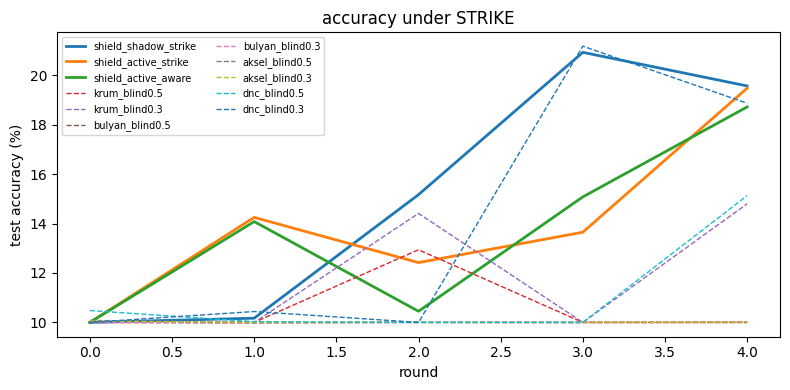

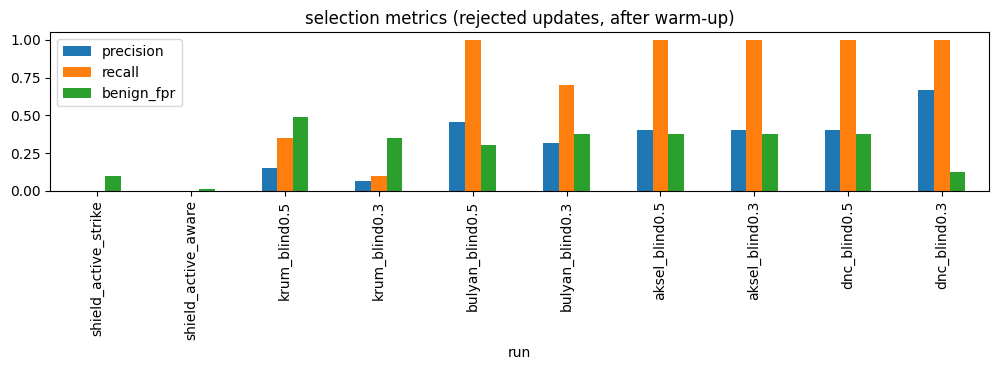

In [9]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 4))
for name, df in runs.items():
    ax.plot(df['round'], df['te_acc'], label=name, lw=2 if name.startswith('shield') else 1, ls='-' if name.startswith('shield') else '--')
ax.set_xlabel('round'); ax.set_ylabel('test accuracy (%)'); ax.legend(fontsize=7, ncol=2); ax.set_title('accuracy under STRIKE')
plt.tight_layout(); plt.show()

# * grouped bars of precision / recall / benign FPR for the runs that have a selection step
sel = summary.dropna(subset=['precision', 'recall', 'benign_fpr'], how='all')
if len(sel):
    sel[['precision', 'recall', 'benign_fpr']].plot.bar(figsize=(10, 3.8), ylim=(0, 1.05))
    plt.title('selection metrics (rejected updates, after warm-up)'); plt.tight_layout(); plt.show()

## 9. SHIELD diagnostics (shadow run): which kernel and feature separates STRIKE?
Mean ground-truth AUC (Byzantine vs benign) per kernel and feature over the shadow run. AUC near 0.5 = no separation, near 1 = clean separation, near 0 = Byzantine looks *more* typical than benign.

In [10]:
# * per-kernel, per-feature AUC from the shadow run
if 'shield_shadow_strike' in runs:
    d = runs['shield_shadow_strike']
    auc_cols = [c for c in d.columns if c.startswith('shield_auc_')]
    recs = []
    for c in auc_cols:
        # * column names look like shield_auc_<kernel>_<feature>, feature in {s, z_low, z_band, z_res}
        m = re.match(r'shield_auc_(.+)_(s|z_low|z_band|z_res)$', c)
        if m:
            recs.append({'kernel': m.group(1), 'feature': m.group(2), 'mean_auc': nanmean(d[c])})
    display(pd.DataFrame(recs).pivot(index='kernel', columns='feature', values='mean_auc').round(2))
else:
    print('no shadow run parsed')

feature,s,z_band,z_low,z_res
kernel,,,,
lin,0.32,0.34,0.22,0.38
rbf0.25,0.80,0.01,0.88,0.12
rbf0.5,0.02,0.00,0.32,0.00
rbf1,0.22,0.15,0.31,0.38
rbf2,0.28,0.34,0.22,0.38
rbf4,0.17,0.19,0.14,0.18


## How to read the results
- **Accuracy:** lower means the attack hurt more. The paper's Table 1 (defenses given the true count) is only a sanity reference, not a target for these blind runs.
- **Recall:** share of the Byzantine updates that were rejected. **Precision:** share of rejections that were Byzantine. **Benign FPR:** share of honest updates rejected.
- **Blind baselines at 0.5** remove up to half the updates every round, so expect high recall but high benign FPR and low precision. The 0.2 runs show the sensitivity to a lower assumed count.
- **Bulyan** reports only its Krum stage as the kept set. **Shadow mode** trains on benign updates only, so its accuracy is not comparable to the other runs.
- **One seed, 30 rounds:** differences of a few points are within noise. Add seeds before drawing conclusions.